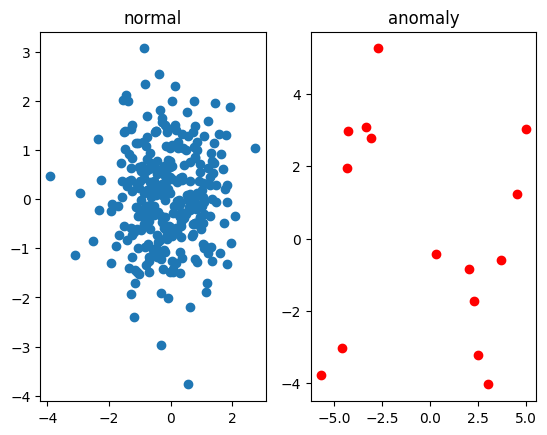

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

rng = np.random.default_rng(0)
normal = rng.normal(0, 1, (300, 2))  # 평균:0, 표준편차:1 로 (300,2) 크기로 데이터 생성
outlier = rng.uniform(-6, 6, (15, 2))    

# 시각화
plt.subplot(1,2,1)
plt.scatter(normal[:,0],normal[:,1])
plt.title('normal')
plt.subplot(1,2,2)
plt.scatter(outlier[:,0],outlier[:,1],c='r')
plt.title('anomaly')
plt.show()


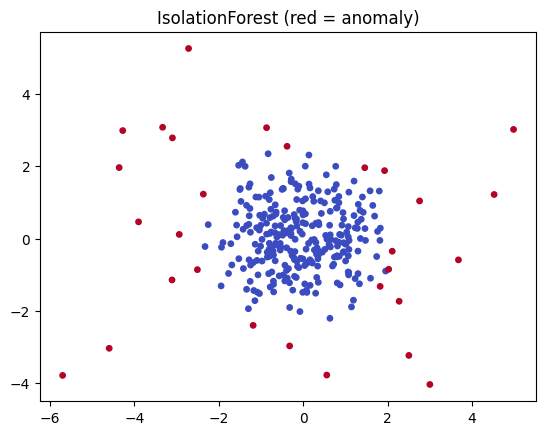

In [ ]:
# 정상데이터 만으로 학습시작
# contamination=0.05 : 전체 중 약 5% 수준을 이상 비율 기준으로 잡는 설정
# 학습 데이터 중 5%가 이상치라고 가정하고, 그 비율에 맞춰 이상판정 기준선(임계값)을 잡아라
iso = IsolationForest(contamination=0.05, random_state=0).fit(normal)

X = np.vstack([normal, outlier]) # 정상과 이상 값을 합한다.
pred = iso.predict(X) # 그리고 예측 시작(1 정상, -1 이상)

# 그리고 예측값을 통해 
plt.scatter(X[:, 0], X[:, 1], c=pred, cmap='coolwarm_r', s=15)
plt.title('IsolationForest (red = anomaly)')
plt.show()